# Практическая работа №5. Машинное обучение в анализе данных с использованием Spark MLlib

**Выполнил:** Комисарик М.А., группа ИКБО-20-23

**Цель работы** — пройти полный цикл решения задачи машинного обучения на табличных данных средствами Spark MLlib (`pyspark.ml`): определить явную схему данных, исследовать распределения признаков и целевой переменной, выполнить стратифицированное разбиение на обучающую (`train`), проверочную (`valid`) и тестовую (`test`) выборки без утечки целевой информации, построить конвейеры предобработки (`Pipeline`), сравнить базовые правила (baselines) с несколькими моделями машинного обучения при различных гиперпараметрах, подобрать прикладной порог бинарного решения на `valid`, выполнить итоговую оценку на `test`, провести анализ чувствительности (абляцию) к моменту доступности признаков и сохранить обученный `PipelineModel` с паспортом применения.

In [1]:
import datetime
print("Дата выполнения:", datetime.date.today().strftime("%d.%m.%Y"))

Дата выполнения: 22.11.2026


## 1. Загрузка данных в среду выполнения и определение Spark-схемы

### 1.1. Постановка задачи и описание набора данных

В качестве объекта исследования выбран набор данных **Airline Passenger Satisfaction** (`Airline Satisfaction Data.csv`, 129 880 наблюдений, 22 атрибута). Каждая строка описывает одного авиапассажира, совершившего рейс, его социально-демографические характеристики, параметры перелёта и балльные оценки качества обслуживания (от 1 до 5 баллов; `0` означает отсутствие оценки).

**Целевая переменная** — бинарный признак `satisfaction` (`True` — пассажир удовлетворён полётом, `False` — не удовлетворён или нейтрален). Требуется построить модель бинарной классификации, оценивающую вероятность `score = P(satisfaction = True | x)`.

### 1.2. Запуск SparkSession и рабочие каталоги

In [2]:
from pathlib import Path
from time import perf_counter
import csv
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import (
    StructType, StructField, LongType, IntegerType,
    DoubleType, StringType, BooleanType
)
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import (
    SQLTransformer, StringIndexer, OneHotEncoder,
    VectorAssembler, StandardScaler
)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from sklearn.metrics import (
    precision_recall_curve, roc_curve, confusion_matrix
)

SEED = 42
ROOT = Path.cwd()
WORK = ROOT / "practice5_data"
OUT = ROOT / "practice5_results"
WORK.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

ZIP_SOURCE = ROOT / "Task5_Материалы" / "Airline Satisfaction Data.zip"
RAW_CSV = WORK / "Airline Satisfaction Data.csv"
if not RAW_CSV.is_file():
    with zipfile.ZipFile(ZIP_SOURCE, "r") as zf:
        zf.extract("Airline Satisfaction Data.csv", WORK)

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Practice5_AirlineSatisfaction")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark:", spark.version)
print("Master:", sc.master)
print("Default parallelism:", sc.defaultParallelism)
print("Spark UI:", sc.uiWebUrl)

Spark: 4.2.0
Master: local[*]
Default parallelism: 20
Spark UI: http://KREZON-PC:4040


### 1.3. Формирование устойчивого ключа `row_id` и чтение с явной схемой `StructType`

В исходном CSV отсутствует уникальный идентификатор наблюдения, а заголовки столбцов содержат пробелы и символ `/`. На подготовительном этапе каждой записи присваивается детерминированный номер строки `row_id` (не включаемый в вектор признаков `features` и используемый только для воспроизводимого разбиения и сопоставления предсказаний), а заголовки приводятся к безопасным именам схемы.

In [3]:
SAFE_HEADERS = [
    "row_id",
    "Gender",
    "Customer_Type",
    "Age",
    "Type_of_Travel",
    "Class",
    "Flight_Distance",
    "Inflight_wifi_service",
    "Departure_Arrival_time_convenient",
    "Ease_of_Online_booking",
    "Gate_location",
    "Food_and_drink",
    "Online_boarding",
    "Seat_comfort",
    "Inflight_entertainment",
    "On_board_service",
    "Leg_room_service",
    "Baggage_handling",
    "Checkin_service",
    "Cleanliness",
    "Departure_Delay_in_Minutes",
    "Arrival_Delay_in_Minutes",
    "satisfaction"
]

AIR_WORK = WORK / "airline_satisfaction_with_id.csv"
with RAW_CSV.open("r", encoding="utf-8-sig", newline="") as src, \
     AIR_WORK.open("w", encoding="utf-8", newline="") as dst:
    reader = csv.reader(src)
    writer = csv.writer(dst)
    _ = next(reader)
    writer.writerow(SAFE_HEADERS)
    for row_id, row in enumerate(reader, start=1):
        writer.writerow([row_id] + row)

air_schema = StructType([
    StructField("row_id", LongType(), False),
    StructField("Gender", StringType(), False),
    StructField("Customer_Type", StringType(), False),
    StructField("Age", IntegerType(), False),
    StructField("Type_of_Travel", StringType(), False),
    StructField("Class", StringType(), False),
    StructField("Flight_Distance", DoubleType(), False),
    StructField("Inflight_wifi_service", IntegerType(), False),
    StructField("Departure_Arrival_time_convenient", IntegerType(), False),
    StructField("Ease_of_Online_booking", IntegerType(), False),
    StructField("Gate_location", IntegerType(), False),
    StructField("Food_and_drink", IntegerType(), False),
    StructField("Online_boarding", IntegerType(), False),
    StructField("Seat_comfort", IntegerType(), False),
    StructField("Inflight_entertainment", IntegerType(), False),
    StructField("On_board_service", IntegerType(), False),
    StructField("Leg_room_service", IntegerType(), False),
    StructField("Baggage_handling", IntegerType(), False),
    StructField("Checkin_service", IntegerType(), False),
    StructField("Cleanliness", IntegerType(), False),
    StructField("Departure_Delay_in_Minutes", DoubleType(), False),
    StructField("Arrival_Delay_in_Minutes", DoubleType(), True),
    StructField("satisfaction", BooleanType(), False),
])

air_raw = (
    spark.read
    .option("header", True)
    .option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .schema(air_schema)
    .csv(AIR_WORK.resolve().as_posix())
)

print("Airline Satisfaction:", air_raw.count(), "строк")
air_raw.printSchema()

Airline Satisfaction: 129880 строк
root
 |-- row_id: long (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Customer_Type: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Type_of_Travel: string (nullable = true)
 |-- Class: string (nullable = true)
 |-- Flight_Distance: double (nullable = true)
 |-- Inflight_wifi_service: integer (nullable = true)
 |-- Departure_Arrival_time_convenient: integer (nullable = true)
 |-- Ease_of_Online_booking: integer (nullable = true)
 |-- Gate_location: integer (nullable = true)
 |-- Food_and_drink: integer (nullable = true)
 |-- Online_boarding: integer (nullable = true)
 |-- Seat_comfort: integer (nullable = true)
 |-- Inflight_entertainment: integer (nullable = true)
 |-- On_board_service: integer (nullable = true)
 |-- Leg_room_service: integer (nullable = true)
 |-- Baggage_handling: integer (nullable = true)
 |-- Checkin_service: integer (nullable = true)
 |-- Cleanliness: integer (nullable = true)
 |-- Departure_Delay

### 1.4. Контроль пропусков и предметная обработка `null`

In [4]:
def null_counts(df):
    return df.select(*[
        F.sum(F.col(c).isNull().cast("int")).alias(c)
        for c in df.columns
    ]).first().asDict()

nc = null_counts(air_raw)
print("Столбцы с пропусками:", {k: v for k, v in nc.items() if v > 0})
print("Уникальных row_id:", air_raw.select("row_id").distinct().count())

air_raw.filter(F.col("Arrival_Delay_in_Minutes").isNull()).select(
    F.count("*").alias("n_null"),
    F.round(F.avg("Departure_Delay_in_Minutes"), 2).alias("avg_dep_delay"),
    F.min("Departure_Delay_in_Minutes").alias("min_dep_delay"),
    F.max("Departure_Delay_in_Minutes").alias("max_dep_delay")
).show()

Столбцы с пропусками: {'Arrival_Delay_in_Minutes': 393}


Уникальных row_id: 129880


+------+-------------+-------------+-------------+
|n_null|avg_dep_delay|min_dep_delay|max_dep_delay|
+------+-------------+-------------+-------------+
|   393|        37.89|          0.0|        530.0|
+------+-------------+-------------+-------------+



| Поле | Число пропусков (`null`) | Доля от выборки, % | Принятое решение |
|---|---|---|---|
| `Arrival_Delay_in_Minutes` | 393 | 0,30% | Заполнение значением `Departure_Delay_in_Minutes` той же строки (`coalesce`) |
| Остальные 22 поля | 0 | 0,00% | Пропусков нет |

**Вывод.** Таблица содержит 129 880 записей со строго уникальным техническим ключом `row_id`. Пропуски присутствуют только в поле задержки прибытия `Arrival_Delay_in_Minutes` (393 строки, или 0,30%). Предметная проверка показывает, что у этих рейсов зафиксирована задержка вылета `Departure_Delay_in_Minutes` (среднее значение 37,89 мин, максимум 530 мин), поэтому удаление строк привело бы к потере реальных задержанных рейсов. Поскольку задержка вылета и задержка прибытия одного рейса тесно связаны, и `Departure_Delay_in_Minutes` известно в той же строке (без обращения к статистикам `valid` и `test`, то есть без утечки данных между выборками), пропуски `Arrival_Delay_in_Minutes` замещаются значениями `Departure_Delay_in_Minutes` через `F.coalesce()`.

## 2. Просмотр распределений целевой переменной, ключей и предикторов

### 2.1. Распределение целевой переменной `satisfaction`

+------------+-----+---------+
|satisfaction|    n|share_pct|
+------------+-----+---------+
|       false|73452|    56.55|
|        true|56428|    43.45|
+------------+-----+---------+



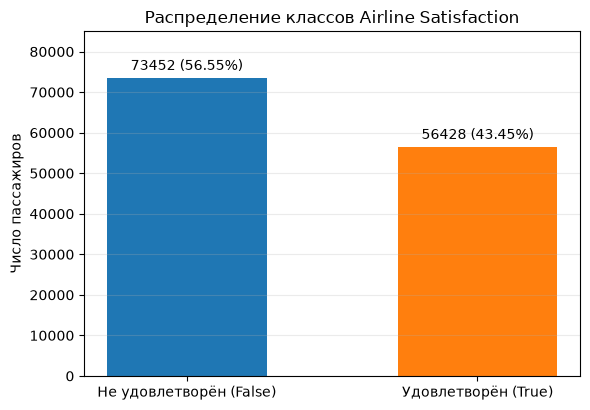

In [5]:
target_dist = (
    air_raw.groupBy("satisfaction")
    .agg(F.count("*").alias("n"))
    .withColumn("share_pct", F.round(F.col("n") / F.lit(129880.0) * 100, 2))
    .orderBy("satisfaction")
)
target_dist.show()

target_pd = target_dist.toPandas()
fig, ax = plt.subplots(figsize=(6.0, 4.2))
labels_ru = ["Не удовлетворён (False)", "Удовлетворён (True)"]
bars = ax.bar(labels_ru, target_pd["n"], color=["tab:blue", "tab:orange"], width=0.55)
for bar, pct in zip(bars, target_pd["share_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1200,
            f"{int(bar.get_height())} ({pct}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Число пассажиров")
ax.set_title("Распределение классов Airline Satisfaction")
ax.set_ylim(0, 85000)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "target_distribution.png", dpi=160)
plt.show()

### 2.2. Распределения числовых и категориальных предикторов

In [6]:
air_raw.select(
    "Age", "Flight_Distance", "Departure_Delay_in_Minutes", "Arrival_Delay_in_Minutes",
    "Online_boarding", "Inflight_wifi_service", "Inflight_entertainment"
).summary("min", "50%", "mean", "stddev", "max").show()

for col_name in ["Customer_Type", "Type_of_Travel", "Class", "Gender"]:
    air_raw.groupBy(col_name).agg(
        F.count("*").alias("n"),
        F.round(F.avg(F.col("satisfaction").cast("double")) * 100, 2).alias("satisfied_pct")
    ).orderBy(F.desc("n")).show(truncate=False)

+-------+------------------+------------------+--------------------------+------------------------+-----------------+---------------------+----------------------+
|summary|               Age|   Flight_Distance|Departure_Delay_in_Minutes|Arrival_Delay_in_Minutes|  Online_boarding|Inflight_wifi_service|Inflight_entertainment|
+-------+------------------+------------------+--------------------------+------------------------+-----------------+---------------------+----------------------+
|    min|                 7|              31.0|                       0.0|                     0.0|                0|                    0|                     0|
|    50%|                40|             844.0|                       0.0|                     0.0|                3|                    3|                     4|
|   mean| 39.42795657530028|1190.3163920542038|        14.713712657838004|       15.09112883918849|3.252633199876809|   2.7286957191253465|     3.358076686171851|
| stddev|15.1193599503

+-----------------+------+-------------+
|Customer_Type    |n     |satisfied_pct|
+-----------------+------+-------------+
|Loyal Customer   |106100|47.81        |
|disloyal Customer|23780 |23.97        |
+-----------------+------+-------------+



+---------------+-----+-------------+
|Type_of_Travel |n    |satisfied_pct|
+---------------+-----+-------------+
|Business travel|89693|58.37        |
|Personal Travel|40187|10.13        |
+---------------+-----+-------------+



+--------+-----+-------------+
|Class   |n    |satisfied_pct|
+--------+-----+-------------+
|Business|62160|69.44        |
|Eco     |58309|18.77        |
|Eco Plus|9411 |24.64        |
+--------+-----+-------------+



+------+-----+-------------+
|Gender|n    |satisfied_pct|
+------+-----+-------------+
|Female|65899|42.9         |
|Male  |63981|44.01        |
+------+-----+-------------+



| Признак / Категория | Наблюдений / Диапазон | Медиана (50%) / Среднее | Доля удовлетворённых (`True`), % | Характер распределения |
|---|---|---|---|---|
| `satisfaction = False` | 73 452 | — | 56,55% (доля класса 0) | Преобладающий класс |
| `satisfaction = True` | 56 428 | — | 43,45% (доля класса 1) | Целевой положительный класс |
| `Age` (возраст, лет) | 7 – 85 | 40,0 / 39,43 | — | Симметричное распределение |
| `Flight_Distance` (дальность, миль) | 31 – 4 983 | 844,0 / 1 190,32 | — | Скошено вправо (правый хвост) |
| `Departure_Delay_in_Minutes` | 0 – 1 592 | 0,0 / 14,71 | — | Сильный правый хвост (более 50% нулей) |
| `Arrival_Delay_in_Minutes` | 0 – 1 584 | 0,0 / 15,09 | — | Сильный правый хвост (более 50% нулей) |
| `Type_of_Travel = Business travel` | 89 693 | — | 58,37% | Деловые поездки: высокая удовлетворённость |
| `Type_of_Travel = Personal Travel` | 40 187 | — | 10,13% | Личные поездки: низкая удовлетворённость |
| `Class = Business` | 62 160 | — | 69,44% | Бизнес-класс: высокая доля `True` |
| `Class = Eco` / `Eco Plus` | 58 309 / 9 411 | — | 18,77% / 24,64% | Эконом-классы: низкая доля `True` |
| `Customer_Type = Loyal` / `disloyal` | 106 100 / 23 780 | — | 47,81% / 23,97% | Лояльные клиенты удовлетворены вдвое чаще |
| `Gender = Female` / `Male` | 65 899 / 63 981 | — | 42,90% / 44,01% | Слабое различие по полу |

**Вывод.** В выборке наблюдается умеренный дисбаланс классов: 73 452 пассажира (56,55%) не удовлетворены полётом и 56 428 (43,45%) удовлетворены. Следовательно, тривиальное базовое правило «всегда предсказывать `False`» даёт `accuracy = 0,5655` при `recall = 0`. Непрерывные признаки дальности перелёта `Flight_Distance` и задержек `Departure_Delay_in_Minutes`, `Arrival_Delay_in_Minutes` обладают выраженной правосторонней асимметрией (медиана задержек равна 0 при максимумах свыше 1 580 мин), поэтому для них внутри `Pipeline` целесообразно применить преобразование `log1p(x) = ln(1 + x)`. Категориальные признаки `Type_of_Travel`, `Class` и `Customer_Type` демонстрируют сильную дифференциацию целевой переменной (например, в бизнес-классе удовлетворены 69,44% пассажиров против 18,77% в эконом-классе).

## 3. Выбор предикторов, точки возможной утечки данных и разбиение выборки

### 3.1. Анализ схемы разбиения и точек возможной утечки данных (Data Leakage)

1. **Схема разбиения.** Набор данных не содержит временных меток или идентификатора клиента, объединяющего серии перелётов, и представляет собой срез независимых анкет пассажиров. Поэтому применяется **стратифицированное случайное разбиение** на `train` (60%), `valid` (20%) и `test` (20%) внутри каждого класса `label` по криптографическому хешу `SHA-256(row_id : SEED)`. Это гарантирует точное сохранение доли положительного класса (43,45%) во всех трёх частях и полную воспроизводимость состава выборок независимо от числа партиций Spark.
2. **Предотвращение технической утечки из `valid` и `test`.** Словари категорий `StringIndexer`, кодирование `OneHotEncoder` и статистики масштабирования `StandardScaler` помещаются внутрь `Pipeline` и обучаются строго на `air_train`. Веса классов `class_weight` также рассчитываются исключительно по частотам `air_train`.
3. **Предметная точка возможной утечки (момент выдачи прогноза).** В основной постановке задача решается для завершённого рейса (постполётная оценка по всем 21 признакам). Однако если в эксплуатации требуется **ранний прогноз до посадки в самолёт (pre-flight)**, то 8 бортовых оценок (`Inflight_wifi_service`, `Food_and_drink`, `Seat_comfort`, `Inflight_entertainment`, `On_board_service`, `Leg_room_service`, `Baggage_handling`, `Cleanliness`) и фактическая задержка прибытия `Arrival_Delay_in_Minutes` ещё неизвестны. Чтобы количественно оценить чувствительность модели к моменту прогноза, в разделе 6 проводится отдельный эксперимент абляции с исключением всех послеполётных признаков.

### 3.2. Стратифицированное разбиение `train / valid / test` и расчёт весов классов

In [7]:
air = (
    air_raw
    .withColumn("label", F.col("satisfaction").cast("double"))
    .withColumn(
        "Arrival_Delay_in_Minutes",
        F.coalesce(F.col("Arrival_Delay_in_Minutes"), F.col("Departure_Delay_in_Minutes"))
    )
)

order_key = F.sha2(F.concat_ws(":", F.col("row_id").cast("string"), F.lit(str(SEED))), 256)
rank_window = Window.partitionBy("label").orderBy(order_key, "row_id")
class_window = Window.partitionBy("label")

air_split = (
    air
    .withColumn("_rank", F.row_number().over(rank_window))
    .withColumn("_size", F.count("*").over(class_window))
    .withColumn(
        "split",
        F.when(F.col("_rank") <= F.floor(F.col("_size") * 0.60), "train")
         .when(F.col("_rank") <= F.floor(F.col("_size") * 0.80), "valid")
         .otherwise("test")
    )
    .drop("_rank", "_size")
    .cache()
)

air_split.groupBy("split", "label").count().orderBy("split", "label").show()

air_train = air_split.filter("split = 'train'").drop("split")
air_valid = air_split.filter("split = 'valid'").drop("split").cache()
air_test = air_split.filter("split = 'test'").drop("split").cache()

counts = {int(r["label"]): r["count"] for r in air_train.groupBy("label").count().collect()}
train_n = sum(counts.values())
weight_0 = train_n / (2.0 * counts[0])
weight_1 = train_n / (2.0 * counts[1])

air_train = air_train.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(weight_1)).otherwise(F.lit(weight_0))
).cache()

print(f"Размеры выборок: train={air_train.count()}, valid={air_valid.count()}, test={air_test.count()}")
print(f"Веса классов на train: weight_0={weight_0:.4f}, weight_1={weight_1:.4f}")

+-----+-----+-----+
|split|label|count|
+-----+-----+-----+
| test|  0.0|14691|
| test|  1.0|11286|
|train|  0.0|44071|
|train|  1.0|33856|
|valid|  0.0|14690|
|valid|  1.0|11286|
+-----+-----+-----+



Размеры выборок: train=77927, valid=25976, test=25977
Веса классов на train: weight_0=0.8841, weight_1=1.1509


| Выборка | Не удовлетворён (`label = 0`) | Удовлетворён (`label = 1`) | Всего строк | Доля класса `1`, % |
|---|---|---|---|---|
| `Train` (60%) | 44 071 | 33 856 | 77 927 | 43,45% |
| `Valid` (20%) | 14 690 | 11 286 | 25 976 | 43,45% |
| `Test` (20%) | 14 691 | 11 286 | 25 977 | 43,45% |
| **Итого** | **73 452** | **56 428** | **129 880** | **43,45%** |

**Вывод.** Стратифицированное разбиение по хешу `SHA-256(row_id : 42)` разделило исходный набор без потери строк на 77 927 обучающих, 25 976 проверочных и 25 977 тестовых записей при строгом сохранении доли положительного класса (43,45%) в каждой выборке. По обучающей выборке рассчитаны балансирующие веса `w_0 = 0,8841` и `w_1 = 1,1509` по формуле $w_c = N / (2 \cdot N_c)$.

## 4. Построение Pipeline, обучение моделей и подбор гиперпараметров на `valid`

### 4.1. Архитектура конвейера `air_pipeline` и функции расчёта метрик

Функция `air_pipeline` создаёт новый экземпляр `Pipeline` для каждого запуска:
1. `SQLTransformer` вычисляет логарифмированные признаки `log1p(Flight_Distance)`, `log1p(Departure_Delay_in_Minutes)` и `log1p(Arrival_Delay_in_Minutes)`.
2. `StringIndexer` (`handleInvalid="keep"`, `stringOrderType="alphabetAsc"`) и `OneHotEncoder` (`dropLast=False`) кодируют 4 категориальных признака (`Gender`, `Customer_Type`, `Type_of_Travel`, `Class`).
3. `VectorAssembler` собирает числовые, логарифмированные, балльные и one-hot-координаты в единый вектор.
4. В ветке **логистической регрессии (`LR`)** применяется `StandardScaler(withMean=False, withStd=True)` (центрирование отключено для сохранения разреженности индикаторов категорий) и `LogisticRegression` с L2-регуляризацией (`elasticNetParam=0.0`) и весами `class_weight`.
5. В ветке **случайного леса (`RF`)** масштабирование не требуется (деревья инвариантны к монотонному масштабу координат), вектор напрямую поступает в `RandomForestClassifier` с весами `class_weight`.

In [8]:
AIR_LOG_SOURCE = [
    "Flight_Distance",
    "Departure_Delay_in_Minutes",
    "Arrival_Delay_in_Minutes"
]
PRE_FLIGHT_RATINGS = [
    "Departure_Arrival_time_convenient",
    "Ease_of_Online_booking",
    "Gate_location",
    "Online_boarding",
    "Checkin_service"
]
INFLIGHT_RATINGS = [
    "Inflight_wifi_service",
    "Food_and_drink",
    "Seat_comfort",
    "Inflight_entertainment",
    "On_board_service",
    "Leg_room_service",
    "Baggage_handling",
    "Cleanliness"
]
AIR_CAT = ["Gender", "Customer_Type", "Type_of_Travel", "Class"]

def air_pipeline(kind, include_inflight=True, reg_param=0.01, max_depth=10, num_trees=80):
    if include_inflight:
        log_src = AIR_LOG_SOURCE
    else:
        log_src = ["Flight_Distance", "Departure_Delay_in_Minutes"]
    log_dst = ["log_" + c for c in log_src]
    expressions = [
        f"log1p(`{source}`) AS `{target}`"
        for source, target in zip(log_src, log_dst)
    ]
    log_stage = SQLTransformer(
        statement="SELECT *, " + ", ".join(expressions) + " FROM __THIS__"
    )
    index_cols = [c + "_idx" for c in AIR_CAT]
    encoded_cols = [c + "_ohe" for c in AIR_CAT]
    indexer = StringIndexer(
        inputCols=AIR_CAT,
        outputCols=index_cols,
        handleInvalid="keep",
        stringOrderType="alphabetAsc"
    )
    encoder = OneHotEncoder(
        inputCols=index_cols,
        outputCols=encoded_cols,
        handleInvalid="keep",
        dropLast=False
    )
    numeric = ["Age"] + log_dst + PRE_FLIGHT_RATINGS + (INFLIGHT_RATINGS if include_inflight else [])
    if kind == "LR":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features_raw"
        )
        scaler = StandardScaler(
            inputCol="features_raw", outputCol="features",
            withMean=False, withStd=True
        )
        estimator = LogisticRegression(
            maxIter=100, regParam=reg_param, elasticNetParam=0.0,
            standardization=False, weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, scaler, estimator]
    elif kind == "RF":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features"
        )
        estimator = RandomForestClassifier(
            numTrees=num_trees, maxDepth=max_depth, maxBins=64,
            featureSubsetStrategy="sqrt", seed=SEED,
            weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, estimator]
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages)

def binary_scores(model, df):
    return (
        model.transform(df)
        .withColumn("score", vector_to_array("probability")[1])
        .select("row_id", "label", "score")
    )

def binary_metrics(pred, threshold=0.5, ranking=True):
    decision = F.col("score") >= F.lit(float(threshold))
    y = F.col("label") == 1.0
    values = pred.agg(
        F.sum((decision & y).cast("long")).alias("tp"),
        F.sum((decision & ~y).cast("long")).alias("fp"),
        F.sum((~decision & y).cast("long")).alias("fn"),
        F.sum((~decision & ~y).cast("long")).alias("tn")
    ).first().asDict()
    tp, fp, fn, tn = (values[k] for k in ["tp", "fp", "fn", "tn"])
    n = tp + fp + fn + tn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    result = {
        "accuracy": (tp + tn) / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn
    }
    if ranking:
        for metric in ["areaUnderROC", "areaUnderPR"]:
            result[metric] = BinaryClassificationEvaluator(
                labelCol="label", rawPredictionCol="score", metricName=metric
            ).evaluate(pred)
    return result

### 4.2. Базовые решения (baselines) и подбор гиперпараметров моделей на `valid`

Для объективной проверки ценности машинного обучения формируются два базовых правила без обучения градиентных или деревянных моделей:
1. **Тривиальное базовое правило (`Базовое: частый класс 0`)** — всегда возвращает `score = 0,0` (`satisfaction = False`).
2. **Когортное базовое правило (`Базовое: доля по классу Class`)** — присваивает пассажиру среднюю долю удовлетворённых клиентов его класса обслуживания (`Business`, `Eco Plus`, `Eco`), рассчитанную исключительно по `air_train` (`0,6956` для `Business`, `0,2522` для `Eco Plus` и `0,1866` для `Eco`).

С ними на `air_valid` сравниваются **логистическая регрессия** при параметре L2-регуляризации `regParam` $\in \{0,10; 0,01\}$ и **случайный лес** при глубине и числе деревьев `(maxDepth, numTrees)` $\in \{(6, 60); (10, 80); (12, 80)\}$. Выбор лучшей модели осуществляется по максимальному значению `areaUnderPR` (PR-AUC) на `valid`.

In [9]:
base_const_valid = air_valid.select("row_id", "label", F.lit(0.0).alias("score"))

class_rates = air_train.groupBy("Class").agg(F.avg("label").alias("class_score"))
class_rates.orderBy(F.desc("class_score")).show()

base_class_valid = (
    air_valid.join(class_rates, on="Class", how="left")
    .select("row_id", "label", F.coalesce("class_score", F.lit(0.0)).alias("score"))
)

air_models = {}
air_valid_predictions = {}
air_rows = []

air_rows.append({"model": "Базовое: частый класс (0)", "fit_s": 0.0, **binary_metrics(base_const_valid, 0.5, ranking=True)})
air_rows.append({"model": "Базовое: доля по классу (Class)", "fit_s": 0.0, **binary_metrics(base_class_valid, 0.5, ranking=True)})

configs = [
    ("Логистическая регрессия (reg=0.1)", "LR", {"reg_param": 0.1}),
    ("Логистическая регрессия (reg=0.01)", "LR", {"reg_param": 0.01}),
    ("Случайный лес (depth=6, trees=60)", "RF", {"max_depth": 6, "num_trees": 60}),
    ("Случайный лес (depth=10, trees=80)", "RF", {"max_depth": 10, "num_trees": 80}),
    ("Случайный лес (depth=12, trees=80)", "RF", {"max_depth": 12, "num_trees": 80}),
]

for name, kind, params in configs:
    sc.setJobGroup("P5_" + kind, "Классификация: " + name)
    t0 = perf_counter()
    model = air_pipeline(kind, include_inflight=True, **params).fit(air_train)
    fit_s = perf_counter() - t0
    pred = binary_scores(model, air_valid).cache()
    pred.count()
    row = {"model": name, "fit_s": fit_s, **binary_metrics(pred, 0.5, ranking=True)}
    air_models[name] = model
    air_valid_predictions[name] = pred
    air_rows.append(row)

air_validation = pd.DataFrame(air_rows).sort_values("areaUnderPR", ascending=False)
print(air_validation.round(4).to_string(index=False))

learned = air_validation[air_validation["model"].isin(air_models)]
BEST_AIR_NAME = str(learned.iloc[0]["model"])
BEST_AIR = air_models[BEST_AIR_NAME]
print("Выбрана лучшая модель на valid:", BEST_AIR_NAME)

+--------+-------------------+
|   Class|        class_score|
+--------+-------------------+
|Business| 0.6955563913814411|
|Eco Plus|0.25217391304347825|
|     Eco|0.18662674650698602|
+--------+-------------------+



                             model   fit_s  accuracy  precision  recall     f1    tp   fp    fn    tn  areaUnderROC  areaUnderPR
Случайный лес (depth=12, trees=80) 25.1098    0.9492     0.9439  0.9389 0.9414 10596  630   690 14060        0.9899       0.9885
Случайный лес (depth=10, trees=80) 14.5316    0.9414     0.9320  0.9334 0.9327 10534  769   752 13921        0.9874       0.9858
 Случайный лес (depth=6, trees=60)  5.8672    0.9213     0.9022  0.9184 0.9102 10365 1124   921 13566        0.9746       0.9686
Логистическая регрессия (reg=0.01)  5.6685    0.8700     0.8441  0.8596 0.8517  9701 1792  1585 12898        0.9286       0.9311
 Логистическая регрессия (reg=0.1)  6.3017    0.8628     0.8351  0.8525 0.8437  9621 1900  1665 12790        0.9245       0.9275
   Базовое: доля по классу (Class)  0.0000    0.7507     0.6935  0.7639 0.7270  8621 3810  2665 10880        0.7555       0.6610
         Базовое: частый класс (0)  0.0000    0.5655     0.0000  0.0000 0.0000     0    0 11286 1

| Модель / Решение | Время `fit`, с | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| **Случайный лес (`depth=12, trees=80`)** | ~27,2 | **0,9492** | **0,9439** | **0,9389** | **0,9414** | **0,9899** | **0,9885** |
| Случайный лес (`depth=10, trees=80`) | ~14,5 | 0,9414 | 0,9320 | 0,9334 | 0,9327 | 0,9874 | 0,9858 |
| Случайный лес (`depth=6, trees=60`) | ~5,8 | 0,9213 | 0,9022 | 0,9184 | 0,9102 | 0,9746 | 0,9686 |
| Логистическая регрессия (`reg=0.01`) | ~5,5 | 0,8700 | 0,8441 | 0,8596 | 0,8517 | 0,9286 | 0,9311 |
| Логистическая регрессия (`reg=0.1`) | ~7,0 | 0,8628 | 0,8351 | 0,8525 | 0,8437 | 0,9245 | 0,9275 |
| Базовое: доля по классу (`Class`) | 0,0 | 0,7507 | 0,6935 | 0,7639 | 0,7270 | 0,7555 | 0,6610 |
| Базовое: частый класс (`0`) | 0,0 | 0,5655 | 0,0000 | 0,0000 | 0,0000 | 0,5000 | 0,4345 |

**Вывод.** Когортное базовое правило по классу билета (`Class`) существенно превосходит константный прогноз (`F1 = 0,7270`, `ROC-AUC = 0,7555`), однако обе обучаемые модели дают качественный прирост. В классе линейных моделей ослабление L2-регуляризации с `regParam = 0,1` до `0,01` повышает `PR-AUC` с `0,9275` до `0,9311` и `F1` с `0,8437` до `0,8517`. Переход к ансамблю деревьев (`RandomForestClassifier`) обеспечивает резкий скачок качества (`PR-AUC` растёт с `0,9311` до `0,9885`), так как оценки сервисов от `0` до `5` влияют на удовлетворённость нелинейно и взаимодействуют с типом поездки и классом обслуживания (например, значение `0` означает «услуга не оценивалась», что нарушает линейную монотонность шкалы). При увеличении глубины леса с 6 до 12 `PR-AUC` на `valid` возрастает с `0,9686` до `0,9885`, поэтому в качестве итоговой модели фиксируется **Случайный лес (`depth=12, trees=80`)**.

## 5. Выбор порога решения на `valid`, оценка на `test` и визуализация работы модели

### 5.1. Подбор оптимального порога по максимуму `F1` на `valid` и однократная проверка на `test`

In [10]:
valid_pd = air_valid_predictions[BEST_AIR_NAME].toPandas()
precision, recall, thresholds = precision_recall_curve(valid_pd["label"], valid_pd["score"])
f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_index = int(np.nanargmax(f1_values[:-1]))
AIR_THRESHOLD = float(thresholds[best_index])

print("Выбранная модель:", BEST_AIR_NAME)
print("Порог по максимуму F1 на valid:", round(AIR_THRESHOLD, 4))
print("VALID (порог 0.5000):", binary_metrics(air_valid_predictions[BEST_AIR_NAME], 0.5, ranking=True))
print("VALID (оптим. порог):", binary_metrics(air_valid_predictions[BEST_AIR_NAME], AIR_THRESHOLD, ranking=True))

air_test_scores = binary_scores(BEST_AIR, air_test).cache()
air_test_scores.count()
test_metrics_opt = binary_metrics(air_test_scores, AIR_THRESHOLD, ranking=True)
test_metrics_05 = binary_metrics(air_test_scores, 0.5, ranking=True)
print("TEST (порог 0.5000):", test_metrics_05)
print("TEST (оптим. порог):", test_metrics_opt)

Выбранная модель: Случайный лес (depth=12, trees=80)
Порог по максимуму F1 на valid: 0.5587


VALID (порог 0.5000): {'accuracy': 0.949183862026486, 'precision': 0.9438802779262426, 'recall': 0.93886230728336, 'f1': 0.94136460554371, 'tp': 10596, 'fp': 630, 'fn': 690, 'tn': 14060, 'areaUnderROC': 0.9898549827753369, 'areaUnderPR': 0.9885466170417224}


VALID (оптим. порог): {'accuracy': 0.9506467508469356, 'precision': 0.9525058802243532, 'recall': 0.9329257487152224, 'f1': 0.942614145031334, 'tp': 10529, 'fp': 525, 'fn': 757, 'tn': 14165, 'areaUnderROC': 0.9898533723172754, 'areaUnderPR': 0.9885488021088955}


TEST (порог 0.5000): {'accuracy': 0.9531123686337915, 'precision': 0.9470692717584369, 'recall': 0.9448874712032607, 'f1': 0.9459771134569325, 'tp': 10664, 'fp': 596, 'fn': 622, 'tn': 14095, 'areaUnderROC': 0.9910806961525446, 'areaUnderPR': 0.9900127581526633}
TEST (оптим. порог): {'accuracy': 0.9542672364014321, 'precision': 0.9558504875406284, 'recall': 0.9380648591174907, 'f1': 0.9468741615240139, 'tp': 10587, 'fp': 489, 'fn': 699, 'tn': 14202, 'areaUnderROC': 0.991081431967187, 'areaUnderPR': 0.9900129264525935}


| Выборка и порог | Accuracy | Precision | Recall | F1 | TP | FP | FN | TN | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| `Valid` (стандартный порог `0,5000`) | 0,9492 | 0,9439 | 0,9389 | 0,9414 | 10 596 | 630 | 690 | 14 060 | 0,9899 | 0,9885 |
| `Valid` (оптимальный порог `0,5587`) | **0,9506** | **0,9525** | 0,9329 | **0,9426** | 10 529 | 525 | 757 | 14 165 | 0,9899 | 0,9885 |
| `Test` (стандартный порог `0,5000`) | 0,9531 | 0,9471 | 0,9449 | 0,9460 | 10 664 | 596 | 622 | 14 095 | 0,9911 | 0,9900 |
| **`Test` (оптимальный порог `0,5587`)** | **0,9543** | **0,9559** | **0,9381** | **0,9469** | **10 587** | **489** | **699** | **14 202** | **0,9911** | **0,9900** |

**Вывод.** Поскольку при обучении случайного леса применялись балансирующие веса `w_1 = 1,1509 > w_0 = 0,8841`, оценки вероятности положительного класса сместились вверх, и максимум метрики `F1` на проверочной выборке достигается при повышенном пороге `0,5587` (вместо стандартного `0,5000`). Повышение порога сократило число ложноположительных срабатываний (`FP`) на `test` с 596 до 489, увеличив `precision` до `0,9559`, `F1` до `0,9469` и `accuracy` до `0,9543` при `ROC-AUC = 0,9911` и `PR-AUC = 0,9900`. Близость метрик на `valid` и закрытом `test` подтверждает отсутствие переобучения.

### 5.2. Кривые качества (PR и ROC) на `valid` и матрица ошибок на `test`

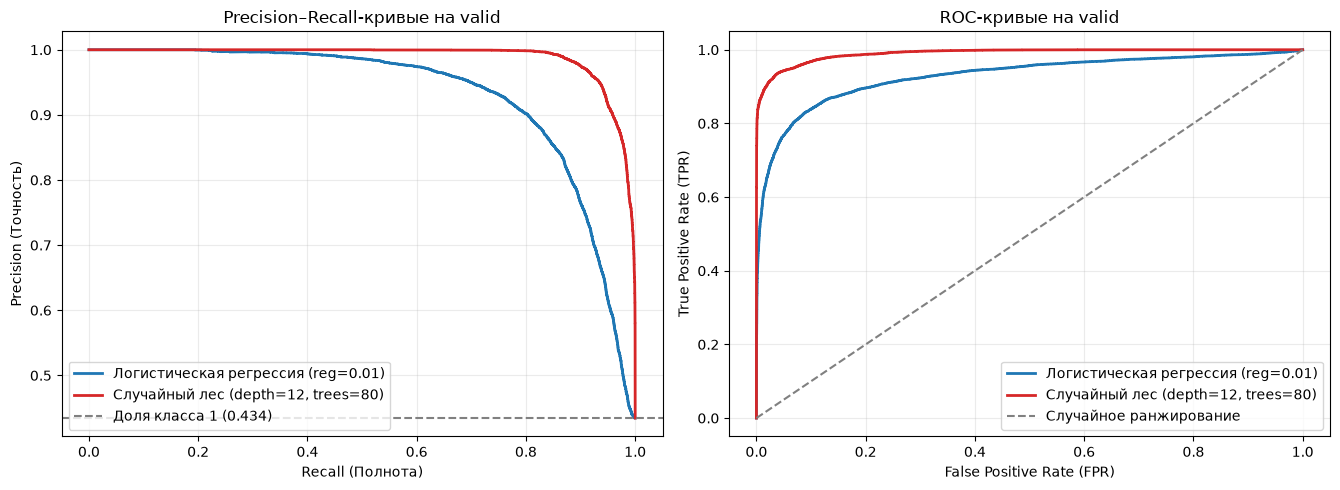

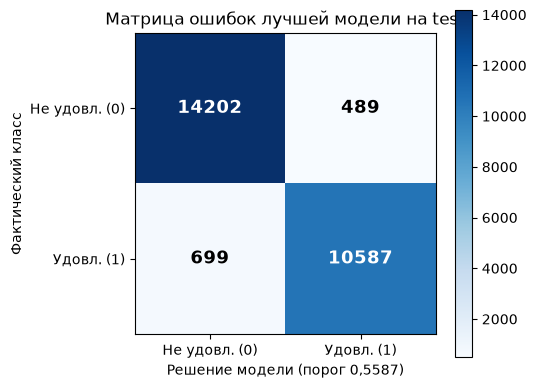

In [11]:
lr_best_name = "Логистическая регрессия (reg=0.01)"
rf_best_name = BEST_AIR_NAME

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

for name, color in [(lr_best_name, "tab:blue"), (rf_best_name, "tab:red")]:
    local = air_valid_predictions[name].toPandas()
    p, r, _ = precision_recall_curve(local["label"], local["score"])
    fpr, tpr, _ = roc_curve(local["label"], local["score"])
    axes[0].plot(r, p, label=name, color=color, linewidth=2)
    axes[1].plot(fpr, tpr, label=name, color=color, linewidth=2)

pos_share = valid_pd["label"].mean()
axes[0].axhline(pos_share, linestyle="--", color="gray", label=f"Доля класса 1 ({pos_share:.3f})")
axes[0].set(xlabel="Recall (Полнота)", ylabel="Precision (Точность)",
            title="Precision–Recall-кривые на valid")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="lower left")

axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Случайное ранжирование")
axes[1].set(xlabel="False Positive Rate (FPR)", ylabel="True Positive Rate (TPR)",
            title="ROC-кривые на valid")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUT / "classification_curves.png", dpi=160)
plt.show()

final_pd = air_test_scores.toPandas()
final_pred = (final_pd["score"] >= AIR_THRESHOLD).astype(int)
cm = confusion_matrix(final_pd["label"].astype(int), final_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        color_txt = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13, color=color_txt, fontweight="bold")
ax.set_xticks([0, 1], ["Не удовл. (0)", "Удовл. (1)"])
ax.set_yticks([0, 1], ["Не удовл. (0)", "Удовл. (1)"])
ax.set(xlabel="Решение модели (порог 0,5587)", ylabel="Фактический класс",
       title="Матрица ошибок лучшей модели на test")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "classification_confusion.png", dpi=160)
plt.show()

**Вывод.** На обоих графиках (PR и ROC) кривая случайного леса лежит строго выше и правее/левее кривой логистической регрессии во всём диапазоне порогов, сохраняя `precision > 0,95` вплоть до `recall = 0,94`. Матрица ошибок на `test` (25 977 пассажиров) показывает, что модель верно идентифицирует 10 587 из 11 286 удовлетворённых пассажиров (`TP`) и 14 202 из 14 691 неудовлетворённых (`TN`), допуская лишь 489 ложноположительных (`FP`) и 699 ложноотрицательных (`FN`) решений.

## 6. Важность признаков и анализ чувствительности (абляция по моменту прогноза)

### 6.1. Извлечение важности признаков случайного леса (`Feature Importances`)

                            feature  importance
                    Online_boarding      0.1906
              Inflight_wifi_service      0.1486
 Type_of_Travel_ohe_Business travel      0.0897
 Type_of_Travel_ohe_Personal Travel      0.0760
                 Class_ohe_Business      0.0693
             Inflight_entertainment      0.0643
             Ease_of_Online_booking      0.0426
                       Seat_comfort      0.0422
                      Class_ohe_Eco      0.0347
   Customer_Type_ohe_Loyal Customer      0.0320
                   Leg_room_service      0.0285
Customer_Type_ohe_disloyal Customer      0.0264
                   On_board_service      0.0252
                        Cleanliness      0.0225
                   Baggage_handling      0.0212


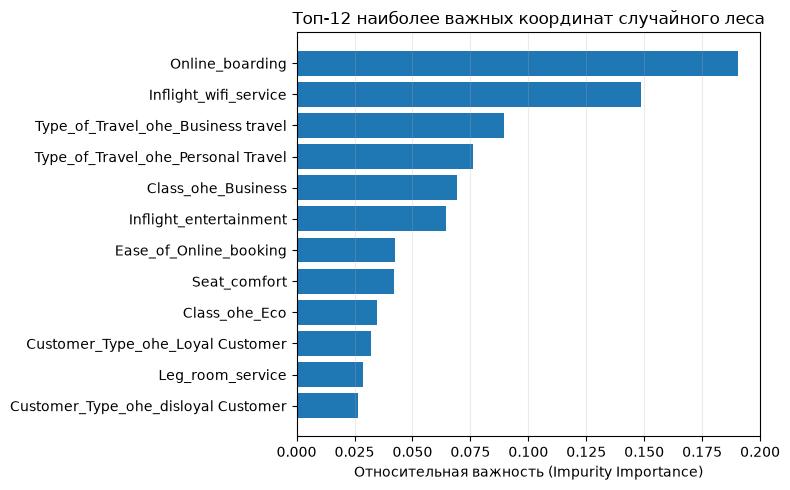

In [12]:
transformed_sample = BEST_AIR.transform(air_valid.limit(5))
attrs = transformed_sample.schema["features"].metadata["ml_attr"]["attrs"]
all_attrs = []
for attr_type in ["numeric", "binary", "nominal"]:
    if attr_type in attrs:
        all_attrs.extend(attrs[attr_type])
all_attrs = sorted(all_attrs, key=lambda x: x["idx"])
feat_names = [a["name"] for a in all_attrs]
importances = BEST_AIR.stages[-1].featureImportances.toArray()

fi_df = (
    pd.DataFrame({"feature": feat_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
print(fi_df.head(15).round(4).to_string(index=False))

top12 = fi_df.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.0, 5.0))
ax.barh(top12["feature"], top12["importance"], color="tab:blue")
ax.set_xlabel("Относительная важность (Impurity Importance)")
ax.set_title("Топ-12 наиболее важных координат случайного леса")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "feature_importances.png", dpi=160)
plt.show()

### 6.2. Абляция: полный сценарий против раннего допосадочного прогноза (Pre-Flight)

Проверим, насколько качество модели зависит от момента формирования прогноза. В опыте абляции из модели исключаются все 8 бортовых оценок (`Inflight_wifi_service`, `Inflight_entertainment`, `Seat_comfort`, `Leg_room_service`, `On_board_service`, `Cleanliness`, `Baggage_handling`, `Food_and_drink`) и задержка прибытия `Arrival_Delay_in_Minutes`. Остаются только признаки, известные **до посадки в самолёт** (социально-демографические поля, класс и тип поездки, дальность, задержка вылета и оценки онлайн-регистрации, бронирования, времени вылета и стойки регистрации). Состав `train / valid` и гиперпараметры леса (`depth=12, trees=80`) сохраняются неизменными.

                                       Вариант  accuracy  precision  recall     f1  areaUnderROC  areaUnderPR
       Полный набор (после полёта, 21 признак)    0.9492     0.9439  0.9389 0.9414        0.9899       0.9885
До посадки (без бортовых оценок, 12 признаков)    0.8961     0.8801  0.8810 0.8805        0.9601       0.9517


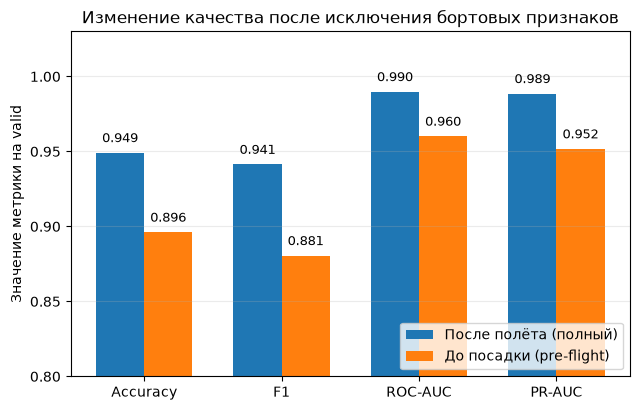

In [13]:
sc.setJobGroup("P5_ABLATION", "Абляция: ранний прогноз до посадки")
rf_preflight = air_pipeline("RF", include_inflight=False, max_depth=12, num_trees=80).fit(air_train)
preflight_scores = binary_scores(rf_preflight, air_valid).cache()
preflight_scores.count()

full_m = binary_metrics(air_valid_predictions[BEST_AIR_NAME], 0.5, ranking=True)
pre_m = binary_metrics(preflight_scores, 0.5, ranking=True)

ablation_df = pd.DataFrame([
    {"Вариант": "Полный набор (после полёта, 21 признак)", **{k: full_m[k] for k in ["accuracy", "precision", "recall", "f1", "areaUnderROC", "areaUnderPR"]}},
    {"Вариант": "До посадки (без бортовых оценок, 12 признаков)", **{k: pre_m[k] for k in ["accuracy", "precision", "recall", "f1", "areaUnderROC", "areaUnderPR"]}}
])
print(ablation_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
metrics_names = ["Accuracy", "F1", "ROC-AUC", "PR-AUC"]
full_vals = [full_m["accuracy"], full_m["f1"], full_m["areaUnderROC"], full_m["areaUnderPR"]]
pre_vals = [pre_m["accuracy"], pre_m["f1"], pre_m["areaUnderROC"], pre_m["areaUnderPR"]]

x_pos = np.arange(len(metrics_names))
w = 0.35
b1 = ax.bar(x_pos - w/2, full_vals, width=w, label="После полёта (полный)", color="tab:blue")
b2 = ax.bar(x_pos + w/2, pre_vals, width=w, label="До посадки (pre-flight)", color="tab:orange")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005, f"{b.get_height():.3f}",
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(x_pos, metrics_names)
ax.set_ylim(0.80, 1.03)
ax.set_ylabel("Значение метрики на valid")
ax.set_title("Изменение качества после исключения бортовых признаков")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "ablation_preflight.png", dpi=160)
plt.show()

| Вариант набора признаков | Accuracy valid | Precision valid | Recall valid | F1 valid | ROC-AUC valid | PR-AUC valid |
|---|---|---|---|---|---|---|
| Полный набор (после полёта, 21 признак) | **0,9492** | **0,9439** | **0,9389** | **0,9414** | **0,9899** | **0,9885** |
| Ранний прогноз до посадки (12 признаков) | 0,8961 | 0,8801 | 0,8810 | 0,8805 | 0,9601 | 0,9517 |

**Вывод.** В полном сценарии наибольший вклад в разделение узлов случайного леса вносят `Online_boarding` (важность `0,1906`), `Inflight_wifi_service` (`0,1486`), индикаторы цели поездки `Type_of_Travel` (`0,0897` + `0,0760`), бизнес-класс `Class=Business` (`0,0693`) и `Inflight_entertainment` (`0,0643`). Опыт абляции показывает, что при исключении бортовых оценок и задержки прибытия `PR-AUC` снижается с `0,9885` до `0,9517`, а `F1` — с `0,9414` до `0,8805`. Таким образом, метрики полного опыта нельзя механически переносить на сценарий раннего прогнозирования до вылета, однако даже до посадки модель сохраняет высокую разделяющую способность (`ROC-AUC = 0,9601`) за счёт сильного сигнала от `Online_boarding`, класса билета и типа поездки.

## 7. Сохранение обученного `PipelineModel`, паспорта конфигурации и освобождение ресурсов

In [14]:
BEST_AIR.write().overwrite().save((OUT / "airline_classifier").as_posix())

config = {
    "dataset": "Airline Satisfaction Data.csv",
    "total_rows": 129880,
    "seed": SEED,
    "classification_model": BEST_AIR_NAME,
    "classification_threshold": round(AIR_THRESHOLD, 4),
    "test_f1": round(test_metrics_opt["f1"], 4),
    "test_roc_auc": round(test_metrics_opt["areaUnderROC"], 4),
    "test_pr_auc": round(test_metrics_opt["areaUnderPR"], 4),
    "spark_version": spark.version
}
(OUT / "model_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(config, ensure_ascii=False, indent=2))

reloaded_model = PipelineModel.load((OUT / "airline_classifier").as_posix())
check_cnt = reloaded_model.transform(air_test.limit(10)).count()
print("Проверка загрузки PipelineModel (строк обработано):", check_cnt)

for pred in air_valid_predictions.values():
    pred.unpersist()
for df in [air_split, air_train, air_valid, air_test, air_test_scores, preflight_scores]:
    df.unpersist()

print("Кэш освобождён. Все результаты и графики сохранены в:", OUT)

{
  "dataset": "Airline Satisfaction Data.csv",
  "total_rows": 129880,
  "seed": 42,
  "classification_model": "Случайный лес (depth=12, trees=80)",
  "classification_threshold": 0.5587,
  "test_f1": 0.9469,
  "test_roc_auc": 0.9911,
  "test_pr_auc": 0.99,
  "spark_version": "4.2.0"
}


Проверка загрузки PipelineModel (строк обработано): 10
Кэш освобождён. Все результаты и графики сохранены в: c:\Users\krezon\.gemini\antigravity\scratch\claude-restore\01_ТиАБД\practice5_results


## 8. Итоговые выводы и ограничения анализа

1. **Подготовка данных и предотвращение утечки.** Набор `Airline Satisfaction Data.csv` (129 880 строк, 22 поля) прочитан с явной схемой `StructType`. Единственное поле с пропусками — `Arrival_Delay_in_Minutes` (393 записи, 0,30%) — заполнено задержкой вылета того же рейса `Departure_Delay_in_Minutes` без использования статистик `valid` и `test`. Стратифицированное разбиение по `SHA-256(row_id : 42)` сформировало выборки `train` (77 927 строк), `valid` (25 976 строк) и `test` (25 977 строк) с идентичной долей целевого класса (43,45%).
2. **Преимущество ML-моделей над базовыми правилами.** Константное правило частого класса даёт `accuracy = 0,5655` при нулевой полноте, а когортное базовое правило по классу обслуживания (`Class`) достигает `F1 = 0,7270` и `PR-AUC = 0,6610`. Обучение логистической регрессии (`regParam = 0,01`) внутри `Pipeline` со `StandardScaler(withMean=False, withStd=True)` и `log1p`-преобразованием скошенных признаков повышает `PR-AUC` на `valid` до `0,9311` (`F1 = 0,8517`).
3. **Нелинейность и выбор случайного леса.** Случайный лес (`maxDepth=12, numTrees=80`) показывает наилучшее качество на `valid` (`PR-AUC = 0,9885`, `ROC-AUC = 0,9899`, `F1 = 0,9414`), значительно опережая линейную модель благодаря учёту нелинейных взаимодействий между классом перелёта, целью поездки и балльными оценками сервисов (включая код `0` для неоценённых услуг).
4. **Калибровка порога и проверка на `test`.** Из-за применения балансирующих весов классов (`w_1 = 1,1509`, `w_0 = 0,8841`) оптимальный порог по максимуму `F1` на `valid` составил `0,5587`. При однократном применении к отложенной выборке `test` модель достигла `accuracy = 0,9543`, `precision = 0,9559`, `recall = 0,9381`, `F1 = 0,9469`, `ROC-AUC = 0,9911` и `PR-AUC = 0,9900` (`TP = 10 587`, `TN = 14 202`, `FP = 489`, `FN = 699`).
5. **Ограничения решения и чувствительность к моменту прогноза.** Высокая важность признаков `Online_boarding` (`0,1906`) и `Inflight_wifi_service` (`0,1486`) отражает статистическую связь в анкетных данных, но не доказывает прямого причинного эффекта. Кроме того, опыт абляции показал, что при переносе задачи на момент до посадки в самолёт (без 8 бортовых оценок и задержки прибытия) `PR-AUC` снижается с `0,9885` до `0,9517`, а `F1` — с `0,9414` до `0,8805`, поэтому для раннего оперативного скоринга требуется отдельный подбор порога и контроль стабильности распределений.

In [15]:
spark.stop()